# Chess960 experiment — results

This notebook turns the output of `analyze_960.py` into tables and figures.

**Before running**

```bash
uv run python analyze_960.py --stockfish /opt/homebrew/bin/stockfish   # writes _analysis/games.csv + conditions.csv
uv sync --extra analysis                                                 # matplotlib
uv run --with jupyterlab jupyter lab analysis_960.ipynb
```

**Conditions**

| Label | Start position | Prompt says Chess960? |
|---|---|---|
| Plain chess | normal | no (`--standard`) |
| A1 · standard start | normal (#518) | yes |
| A2 · Chess960 | shuffled | yes |
| A2 · not told | shuffled | no (`--no-variant-hint`) |

**Research questions → sections**

| Research question | Sections |
|---|---|
| RQ1 Do LLMs apply the rules correctly when the starting arrangement changes? | 3 Illegal moves (B2 is the main evidence), 2 Loss causes, 4 Comprehension |
| RQ2 How much does quality drop, and is the drop around opening theory? | 1 Win rate, 5 Move quality, **5b Opening-gap test**, 8 Engine baseline |
| RQ3 Are errors biased towards the standard starting position? | **3b Standard-pattern errors** |

Each figure is split into panels by **legal-move access** (B1/B2) and **opponent** (C1 random / C2 engine), with one figure per model.
Under every figure the same numbers are printed as a table.

In [49]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ANALYSIS_DIR = Path("_analysis")        # output folder of analyze_960.py
LOG_DIR = Path("_logs/chess960")        # raw logs (only used for the engine baseline)
FIG_DIR = ANALYSIS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FIGURES = True

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

# Start-position conditions, in a fixed order with fixed colours (colour follows the condition, never its rank)
START_ORDER = ["standard-chess", "A1-standard-pos518", "A2-chess960", "A2-chess960-uninformed"]
START_LABEL = {
    "standard-chess": "Plain chess",
    "A1-standard-pos518": "A1 · standard start",
    "A2-chess960": "A2 · Chess960",
    "A2-chess960-uninformed": "A2 · not told",
}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # validated palette, fixed order
START_COLOR = dict(zip(START_ORDER, CATEGORICAL))

LOSS_CAUSES = ["checkmate", "illegal_move_forfeit", "format_forfeit", "mixed_forfeit", "max_turns_forfeit", "error"]
LOSS_LABEL = {
    "checkmate": "Checkmated", "illegal_move_forfeit": "Illegal-move forfeit", "format_forfeit": "Format forfeit",
    "mixed_forfeit": "Mixed forfeit", "max_turns_forfeit": "Max-turns forfeit", "error": "Error",
}
ILLEGAL_TYPES = ["castling", "piece_movement", "wrong_piece_on_square", "leaves_king_in_check", "missing_promotion", "unparseable"]
ILLEGAL_LABEL = {
    "castling": "Castling", "piece_movement": "Piece movement", "wrong_piece_on_square": "Wrong piece on square",
    "leaves_king_in_check": "Leaves king in check", "missing_promotion": "Missing promotion", "unparseable": "Unparseable",
}
PHASE_COLOR = {"opening": CATEGORICAL[0], "later": CATEGORICAL[1]}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "legend.frameon": False,
})


def savefig(fig, name):
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## Load the data

In [50]:
games_path = ANALYSIS_DIR / "games.csv"
conditions_path = ANALYSIS_DIR / "conditions.csv"
if not games_path.exists():
    raise FileNotFoundError(
        f"{games_path} not found - run `uv run python analyze_960.py` first (see the top of this notebook)."
    )

games = pd.read_csv(games_path)
conditions = pd.read_csv(conditions_path) if conditions_path.exists() else pd.DataFrame()

def to_bool(v):
    if isinstance(v, str):
        return {"true": True, "false": False}.get(v.strip().lower(), np.nan)
    return v if isinstance(v, (bool, np.bool_)) else np.nan

games["comprehension_checked"] = games["comprehension_checked"].map(to_bool).fillna(False).astype(bool)
games["comprehension_correct"] = games["comprehension_correct"].map(to_bool)
games["start"] = pd.Categorical(games["start"], categories=[s for s in START_ORDER if s in set(games["start"])], ordered=True)
games["panel"] = games["legal_moves"] + " | " + games["opponent"]
games["win"] = (games["result"] == "win").astype(int)
games["draw"] = (games["result"] == "draw").astype(int)
games["loss"] = (games["result"] == "loss").astype(int)

MODELS = sorted(games["model"].unique())
print(f"{len(games)} LLM game-sides, models: {MODELS}")

100 LLM game-sides, models: ['claude-haiku-5-5']


### Games per cell
Check that every cell has the number of games you planned before reading anything else.

In [51]:
counts = (games.groupby(["model", "legal_moves", "opponent", "start"], observed=True).size()
          .unstack("start", fill_value=0).rename(columns=START_LABEL))
counts

start                                                 Plain chess  A1 · standard start  A2 · Chess960  A2 · not told
model            legal_moves       opponent                                                                         
claude-haiku-5-5 B1-legal-moves    C1-random                   10                   11             10              9
                                   C2-stockfish-lvl0            0                   10             10             10
                 B2-no-legal-moves C1-random                    0                   10             10              0
                                   C2-stockfish-lvl0            0                    0             10              0

## Helpers

In [52]:
def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return p, max(0.0, centre - half), min(1.0, centre + half)


def panels_for(df):
    return sorted(df["panel"].unique())


def grouped_bars(ax, table, value_col, lo_col=None, hi_col=None, fmt="{:.0%}", label_values=True):
    # One group per panel, one bar per start condition (fixed colours).
    panels = list(dict.fromkeys(table["panel"]))
    starts = [s for s in START_ORDER if s in set(table["start"])]
    width = 0.8 / max(1, len(starts))
    for j, start in enumerate(starts):
        sub = table[table["start"] == start].set_index("panel").reindex(panels)
        x = np.arange(len(panels)) + (j - (len(starts) - 1) / 2) * width
        vals = sub[value_col].to_numpy(dtype=float)
        yerr = None
        if lo_col and hi_col:
            yerr = np.clip(np.vstack([vals - sub[lo_col].to_numpy(dtype=float),
                                      sub[hi_col].to_numpy(dtype=float) - vals]), 0, None)
        ax.bar(x, vals, width * 0.92, color=START_COLOR[start], label=START_LABEL[start],
               edgecolor="white", linewidth=1, yerr=yerr, error_kw={"elinewidth": 1, "ecolor": "#52514e", "capsize": 2})
        for xi, v in zip(x, vals):
            if np.isnan(v):
                continue
            # value labels only without CI whiskers (they would collide); a zero bar is always labelled
            if (label_values and yerr is None and len(panels) * len(starts) <= 16) or v == 0:
                ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(np.arange(len(panels)))
    ax.set_xticklabels([p.replace(" | ", "\n") for p in panels])
    if len(starts) > 1:
        ax.legend(ncols=len(starts), loc="upper left", bbox_to_anchor=(0, 1.12), fontsize=9)


def stacked_share(ax, table, cats, labels, colors):
    # Horizontal 100% stacked bars, one row per (panel, start).
    rows = list(table.index)
    left = np.zeros(len(rows))
    for cat, color in zip(cats, colors):
        vals = table[cat].to_numpy(dtype=float) if cat in table else np.zeros(len(rows))
        ax.barh(range(len(rows)), vals, left=left, color=color, edgecolor="white", linewidth=1, label=labels[cat])
        left += vals
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"{p.replace(' | ', ' · ')}  —  {START_LABEL.get(s, s)}" for p, s in rows])
    ax.invert_yaxis()
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)

## 1. Outcomes — win rate

Win rate of the LLM with 95% Wilson intervals. Against the random player (C1) this measures whether the model can finish
games legally; against the engine (C2) it measures playing strength.

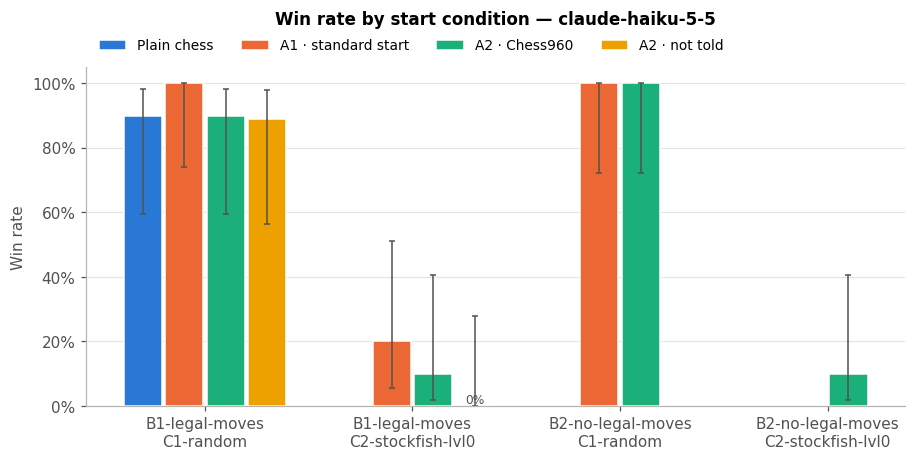

,model,panel,start,games,wins,draws,losses,win_rate,win_lo,win_hi
0,claude-haiku-5-5,B1-legal-moves | C1-random,Plain chess,10,9,1,0,0.900,0.596,0.982
1,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start,11,11,0,0,1.000,0.741,1.000
2,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · Chess960,10,9,1,0,0.900,0.596,0.982
3,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · not told,9,8,1,0,0.889,0.565,0.980
4,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start,10,2,0,8,0.200,0.057,0.510
5,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · Chess960,10,1,0,9,0.100,0.018,0.404
6,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · not told,10,0,2,8,0.000,0.000,0.278
7,claude-haiku-5-5,B2-no-legal-moves | C1-random,A1 · standard start,10,10,0,0,1.000,0.722,1.000
8,claude-haiku-5-5,B2-no-legal-moves | C1-random,A2 · Chess960,10,10,0,0,1.000,0.722,1.000
9,claude-haiku-5-5,B2-no-legal-moves | C2-stockfish-lvl0,A2 · Chess960,10,1,2,7,0.100,0.018,0.404


In [53]:
outcome = (games.groupby(["model", "panel", "start"], observed=True)
           .agg(games=("win", "size"), wins=("win", "sum"), draws=("draw", "sum"), losses=("loss", "sum"))
           .reset_index())
ci = outcome.apply(lambda r: wilson(r["wins"], r["games"]), axis=1, result_type="expand")
outcome[["win_rate", "win_lo", "win_hi"]] = ci

for model in MODELS:
    t = outcome[outcome["model"] == model]
    fig, ax = plt.subplots(figsize=(max(6, 2.4 * t["panel"].nunique()), 4))
    grouped_bars(ax, t, "win_rate", "win_lo", "win_hi")
    ax.set_ylim(0, 1.05); ax.set_ylabel("Win rate"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(f"Win rate by start condition — {model}", pad=28)
    savefig(fig, f"win_rate_{model}"); plt.show()

outcome.assign(start=outcome["start"].map(START_LABEL))

## 2. Why games were lost

Share of the LLM's **losses** by cause. A model that "loses" only by format or illegal-move forfeits has not been beaten at
chess; keep those apart from checkmates when you interpret the win rates above.

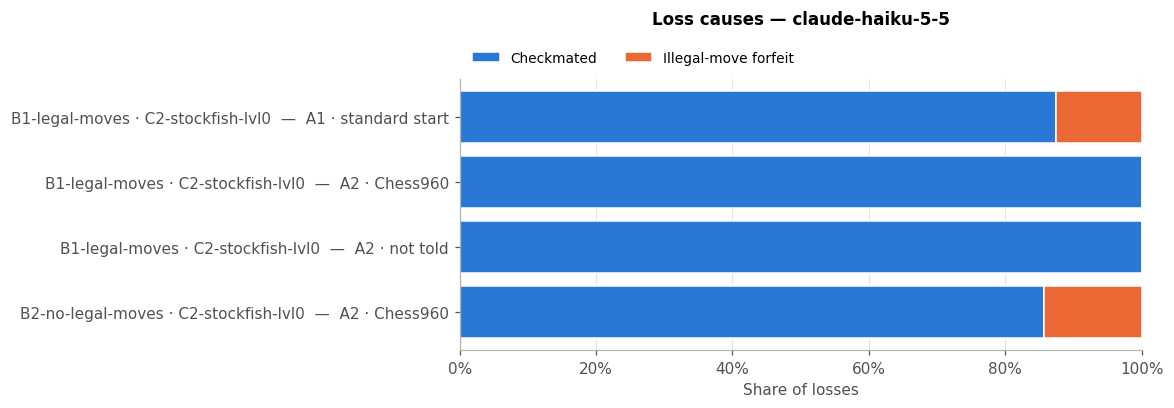

loss_cause                                                                     Checkmated  Illegal-move forfeit
model            panel                                 start                                                   
claude-haiku-5-5 B1-legal-moves | C2-stockfish-lvl0    A1-standard-pos518               7                     1
                                                       A2-chess960                      9                     0
                                                       A2-chess960-uninformed           8                     0
                 B2-no-legal-moves | C2-stockfish-lvl0 A2-chess960                      6                     1

In [54]:
losses = games[games["result"] == "loss"]
if losses.empty:
    print("No losses recorded.")
else:
    cause_tab = (losses.groupby(["model", "panel", "start"], observed=True)["loss_cause"]
                 .value_counts(normalize=True).unstack(fill_value=0))
    for model in MODELS:
        if model not in cause_tab.index.get_level_values(0):
            continue
        t = cause_tab.loc[model]
        cats = [c for c in LOSS_CAUSES if c in t.columns]
        fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.4))
        stacked_share(ax, t, cats, LOSS_LABEL, [CATEGORICAL[LOSS_CAUSES.index(c)] for c in cats])
        ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.set_xlabel("Share of losses")
        ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, 1.0 + 0.9 / (len(t) + 2)), fontsize=9)
        ax.set_title(f"Loss causes — {model}", pad=36)
        savefig(fig, f"loss_causes_{model}"); plt.show()
    display(losses.groupby(["model", "panel", "start"], observed=True)["loss_cause"].value_counts()
            .unstack(fill_value=0).rename(columns=LOSS_LABEL))

## 3. Illegal moves

Illegal move attempts **per LLM turn**, split by type. This is the main rule-knowledge measure and is most informative in B2
(no legal-move list). Castling and *wrong piece on square* errors are the ones that most directly reveal a model playing the
memorised standard setup.

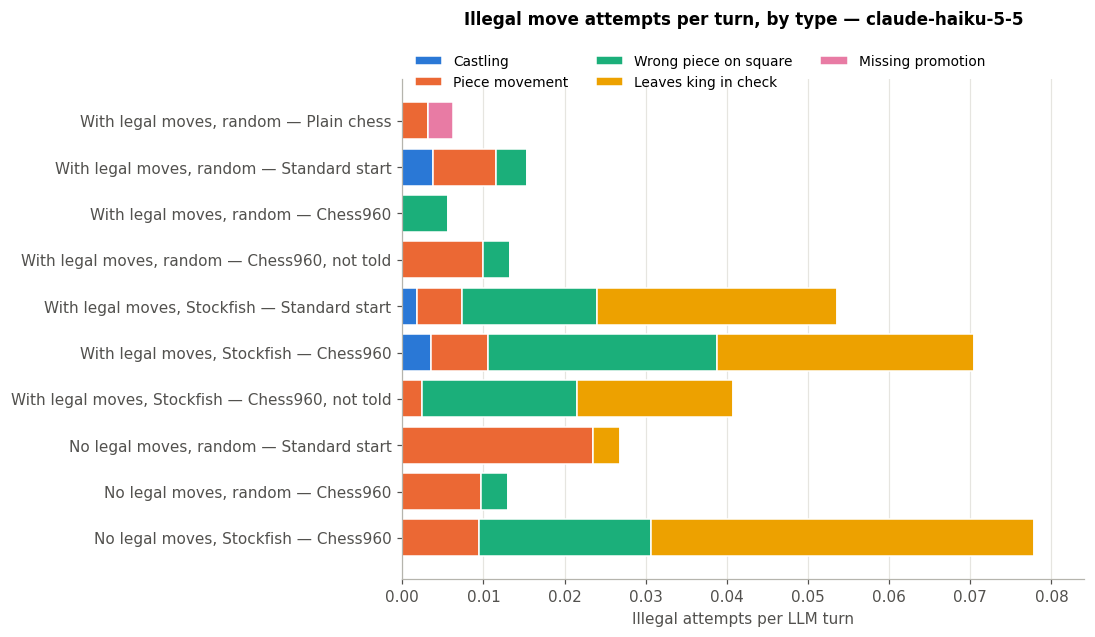

Castling  Piece movement  Wrong piece on square  Leaves king in check  Missing promotion  Unparseable  total
model            panel                                 start                                                                                                                               
claude-haiku-5-5 B1-legal-moves | C1-random            standard-chess             0.000           0.003                  0.000                 0.000              0.003        0.000  0.006
                                                       A1-standard-pos518         0.004           0.008                  0.004                 0.000              0.000        0.000  0.015
                                                       A2-chess960                0.000           0.000                  0.006                 0.000              0.000        0.000  0.006
                                                       A2-chess960-uninformed     0.000           0.010                  0.003                 0.000              0.000        0.000  0.013
                 B1-legal-moves | C2-stockfish-lvl0    A1-standard-pos518         0.002           0.006                  0.017                 0.030              0.000        0.000  0.054
                                                       A2-chess960                0.004           0.007                  0.028                 0.032              0.000        0.000  0.070
                                                       A2-chess960-uninformed     0.000           0.002                  0.019                 0.019              0.000        0.000  0.041
                 B2-no-legal-moves | C1-random         A1-standard-pos518         0.000           0.023                  0.000                 0.003              0.000        0.000  0.027
                                                       A2-chess960                0.000           0.010                  0.003                 0.000              0.000        0.000  0.013
                 B2-no-legal-moves | C2-stockfish-lvl0 A2-chess960                0.000           0.009                  0.021                 0.047              0.000        0.000  0.078

In [65]:
# Readable names for the y-axis (no A1/B1/C1 codes)
NICE_START = {
    "standard-chess": "Plain chess",
    "A1-standard-pos518": "Standard start",
    "A2-chess960": "Chess960",
    "A2-chess960-uninformed": "Chess960, not told",
}

def nice_panel(panel):
    legal, opponent = panel.split(" | ")
    legal = "With legal moves" if legal.startswith("B1") else "No legal moves"
    if opponent.startswith("C1"):
        opponent = "random"
    elif "stockfish" in opponent:
        opponent = "Stockfish"
    elif "dragon" in opponent:
        opponent = "Dragon"
    return f"{legal}, {opponent}"

type_cols = [f"illegal_{t}" for t in ILLEGAL_TYPES if f"illegal_{t}" in games.columns]
illegal = games.groupby(["model", "panel", "start"], observed=True)[type_cols + ["llm_turns"]].sum()
per_turn = illegal[type_cols].div(illegal["llm_turns"].replace(0, np.nan), axis=0)
per_turn.columns = [c.replace("illegal_", "") for c in type_cols]

for model in MODELS:
    if model not in per_turn.index.get_level_values(0):
        continue
    t = per_turn.loc[model]
    if t.to_numpy().sum() == 0:
        print(f"{model}: no illegal move attempts recorded.")
        continue
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.4))
    cats = [c for c in t.columns if t[c].sum() > 0]               # only types that occurred
    colors = [CATEGORICAL[ILLEGAL_TYPES.index(c)] for c in cats]  # colour stays tied to the type
    stacked_share(ax, t, cats, ILLEGAL_LABEL, colors)
    # Replace the coded row labels with readable ones
    ax.set_yticklabels([f"{nice_panel(p)} — {NICE_START.get(s, s)}" for p, s in t.index])
    ax.set_xlim(0, t[cats].sum(axis=1).max() * 1.08)
    ax.set_xlabel("Illegal attempts per LLM turn")
    ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, 1.0 + 0.9 / (len(t) + 2)), fontsize=9)
    ax.set_title(f"Illegal move attempts per turn, by type — {model}", pad=36)
    savefig(fig, f"illegal_moves_{model}"); plt.show()

per_turn.assign(total=per_turn.sum(axis=1)).rename(columns=ILLEGAL_LABEL)

In [67]:
attempts = pd.read_csv(ANALYSIS_DIR / "illegal_attempts.csv")
attempts["phase"] = np.where(attempts["ply"] <= 15, "opening", "later")
key = ["start", "legal_moves", "opponent"]

counts = (attempts.groupby(key + ["phase"]).size()
          .unstack(fill_value=0).reset_index())
turns = (games.assign(start=games["start"].astype(str))
         .groupby(key)[["opening_moves", "later_moves"]].sum().reset_index())

by_phase = turns.merge(counts, on=key, how="left").fillna({"opening": 0, "later": 0})
by_phase["Illegal, plies 1-15"] = by_phase["opening"].astype(int)
by_phase["Illegal, plies 16+"] = by_phase["later"].astype(int)
by_phase["Per turn, plies 1-15"] = (by_phase["opening"] / by_phase["opening_moves"]).round(3)
by_phase["Per turn, plies 16+"] = (by_phase["later"] / by_phase["later_moves"]).round(3)

by_phase["start"] = by_phase["start"].map(NICE_START)
by_phase["setting"] = (by_phase["legal_moves"] + " | " + by_phase["opponent"]).map(nice_panel)
by_phase[["setting", "start", "Illegal, plies 1-15", "Per turn, plies 1-15",
          "Illegal, plies 16+", "Per turn, plies 16+"]]

,setting,start,"Illegal, plies 1-15","Per turn, plies 1-15","Illegal, plies 16+","Per turn, plies 16+"
0,"With legal moves, random",Standard start,3,0.039,1,0.005
1,"With legal moves, Stockfish",Standard start,0,0.000,29,0.062
2,"No legal moves, random",Standard start,0,0.000,8,0.035
3,"With legal moves, random",Chess960,1,0.014,1,0.003
4,"With legal moves, Stockfish",Chess960,0,0.000,20,0.093
5,"No legal moves, random",Chess960,0,0.000,4,0.017
6,"No legal moves, Stockfish",Chess960,0,0.000,33,0.093
7,"With legal moves, random","Chess960, not told",0,0.000,4,0.017
8,"With legal moves, Stockfish","Chess960, not told",2,0.029,15,0.043
9,"With legal moves, random",Plain chess,1,0.014,1,0.004


### First-attempt illegal rate

Share of turns where the model's **first** `make_move` was illegal. Unlike the totals above, this is not cut short by the
forfeit limit, so it is the fairest legality measure for B2.

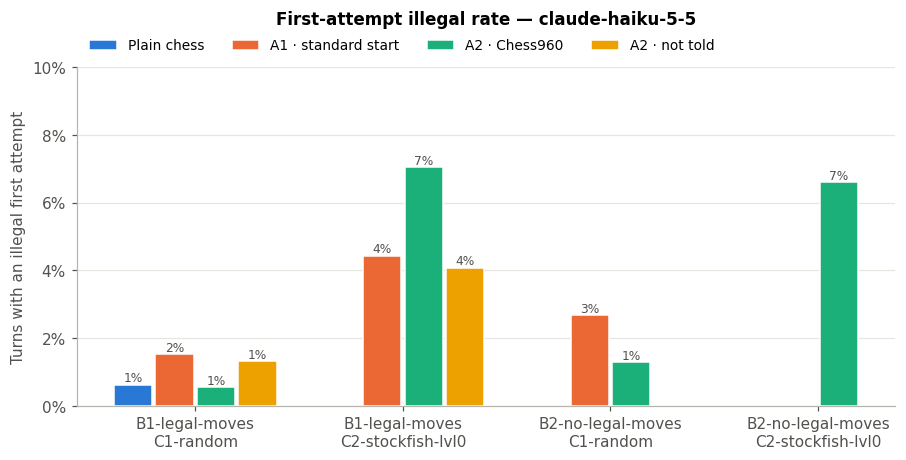

,model,panel,start,first_attempt_illegal_rate,format_normalizations_per_turn
0,claude-haiku-5-5,B1-legal-moves | C1-random,Plain chess,0.006,0.000
1,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start,0.015,0.000
2,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · Chess960,0.006,0.000
3,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · not told,0.013,0.000
4,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start,0.044,0.002
5,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · Chess960,0.070,0.004
6,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · not told,0.041,0.000
7,claude-haiku-5-5,B2-no-legal-moves | C1-random,A1 · standard start,0.027,0.000
8,claude-haiku-5-5,B2-no-legal-moves | C1-random,A2 · Chess960,0.013,0.000
9,claude-haiku-5-5,B2-no-legal-moves | C2-stockfish-lvl0,A2 · Chess960,0.066,0.000


In [56]:
# Turn-weighted average per cell (plain sums, so it works on any pandas version)
tmp = games.assign(_w=games["llm_turns"].clip(lower=1))
tmp["_wfa"] = tmp["first_attempt_illegal_rate"].fillna(0) * tmp["_w"]
first = (tmp.groupby(["model", "panel", "start"], observed=True)
         .agg(_wfa=("_wfa", "sum"), _w=("_w", "sum"), _fmt=("format_normalizations", "sum"), _turns=("llm_turns", "sum"))
         .reset_index())
first["first_attempt_illegal_rate"] = first["_wfa"] / first["_w"]
first["format_normalizations_per_turn"] = first["_fmt"] / first["_turns"].clip(lower=1)
first = first.drop(columns=["_wfa", "_w", "_fmt", "_turns"])

for model in MODELS:
    t = first[first["model"] == model]
    fig, ax = plt.subplots(figsize=(max(6, 2.4 * t["panel"].nunique()), 4))
    grouped_bars(ax, t, "first_attempt_illegal_rate")
    ax.set_ylim(0, max(0.1, t["first_attempt_illegal_rate"].max() * 1.25))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_ylabel("Turns with an illegal first attempt")
    ax.set_title(f"First-attempt illegal rate — {model}", pad=28)
    savefig(fig, f"first_attempt_illegal_{model}"); plt.show()

first.assign(start=first["start"].map(START_LABEL))

## 3b. Standard-pattern errors (RQ3)

Are illegal moves in Chess960 games explained by the **standard** starting position?

* **Phantom-piece move** — the attempt starts on the mover's back rank and would be a valid move for the piece the
  standard setup has on that square, while this game's own start piece there is different (e.g. `g8f6` when g8 holds a
  rook: a knight move from the knight's standard square).
* **Chance rate** — the same test against 100 random *other* Chess960 setups. If the model has no preference for the
  standard setup, the standard setup explains its errors no more often than an arbitrary setup does.
* **Test** — under "no bias" each attempt matches the standard setup with probability equal to its chance rate, so the
  observed count follows a Poisson-binomial distribution; the p-value is the one-sided probability of at least the
  observed count.
* **Standard castling notation** (`e1g1`, `e8c8`, …) is reported separately, for all conditions.

Only Chess960 games (not position 518) can have phantom-piece errors, so A1 and plain chess are absent from the test.

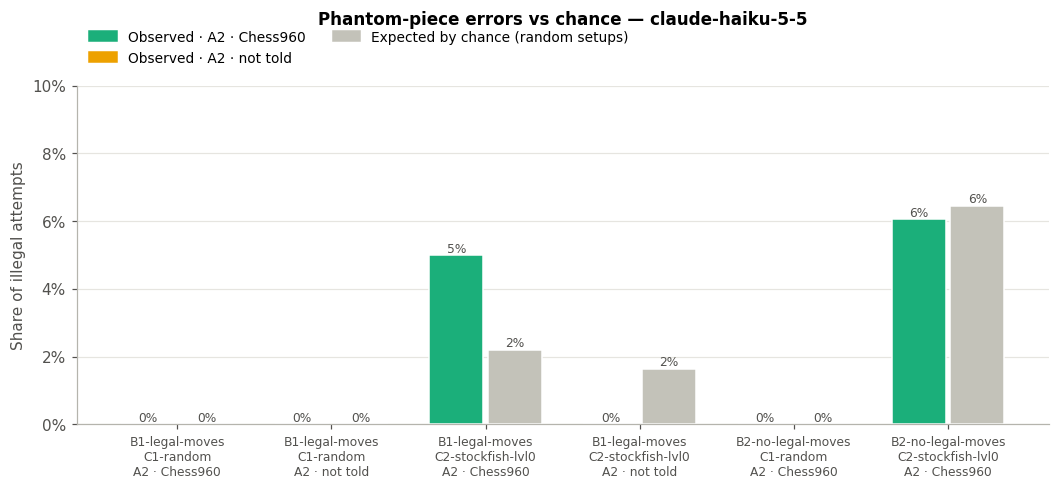

,model,panel,start,attempts,observed,expected_by_chance,observed_share,chance_share,ratio,p_one_sided
0,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · Chess960,2,0,0.000,0.000,0.000,NaN,1.000
1,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · not told,4,0,0.000,0.000,0.000,NaN,1.000
2,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · Chess960,20,1,0.440,0.050,0.022,2.273,0.440
3,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · not told,17,0,0.280,0.000,0.016,0.000,1.000
4,claude-haiku-5-5,B2-no-legal-moves | C1-random,A2 · Chess960,4,0,0.000,0.000,0.000,NaN,1.000
5,claude-haiku-5-5,B2-no-legal-moves | C2-stockfish-lvl0,A2 · Chess960,33,2,2.130,0.061,0.065,0.939,0.697


,model,panel,start,standard_castling_attempts
0,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start,0
1,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · Chess960,0
2,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · not told,0
3,claude-haiku-5-5,B1-legal-moves | C1-random,Plain chess,0
4,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start,1
5,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · Chess960,0
6,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · not told,0
7,claude-haiku-5-5,B2-no-legal-moves | C1-random,A1 · standard start,0
8,claude-haiku-5-5,B2-no-legal-moves | C1-random,A2 · Chess960,0
9,claude-haiku-5-5,B2-no-legal-moves | C2-stockfish-lvl0,A2 · Chess960,0


In [57]:
attempts_path = ANALYSIS_DIR / "illegal_attempts.csv"
attempts = pd.read_csv(attempts_path) if attempts_path.exists() and attempts_path.stat().st_size > 0 else pd.DataFrame()

def poisson_binomial_sf(k, probs):
    # P(X >= k) for X = sum of independent Bernoulli(p_i)
    dist = np.zeros(len(probs) + 1); dist[0] = 1.0
    for p in probs:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[k:].sum())

if attempts.empty:
    print("No illegal move attempts logged.")
else:
    attempts["phantom_standard"] = attempts["phantom_standard"].map(to_bool)
    defined = attempts[attempts["phantom_standard"].notna()].copy()
    defined["panel"] = defined["legal_moves"] + " | " + defined["opponent"]
    rows = []
    for (model, panel, start), g in defined.groupby(["model", "panel", "start"]):
        obs = int(g["phantom_standard"].astype(bool).sum())
        probs = g["phantom_chance"].astype(float).clip(0, 1).to_numpy()
        rows.append({"model": model, "panel": panel, "start": start, "attempts": len(g),
                     "observed": obs, "expected_by_chance": probs.sum(),
                     "observed_share": obs / len(g), "chance_share": probs.mean(),
                     "ratio": obs / probs.sum() if probs.sum() > 0 else np.nan,
                     "p_one_sided": poisson_binomial_sf(obs, probs)})
    sp = pd.DataFrame(rows)
    if sp.empty:
        print("No illegal attempts in Chess960 games yet.")
    else:
        for model in MODELS:
            t = sp[sp["model"] == model]
            if t.empty:
                continue
            labels = [f"{p.replace(' | ', chr(10))}\n{START_LABEL.get(s, s)}" for p, s in zip(t["panel"], t["start"])]
            x = np.arange(len(t)); w = 0.38
            fig, ax = plt.subplots(figsize=(max(6, 1.9 * len(t)), 4))
            ax.bar(x - w / 2, t["observed_share"], w * 0.92, color=[START_COLOR.get(s, CATEGORICAL[0]) for s in t["start"]],
                   edgecolor="white", label="Observed: fits the standard setup")
            ax.bar(x + w / 2, t["chance_share"], w * 0.92, color="#c3c2b9", edgecolor="white",
                   label="Expected by chance (random setups)")
            for xi, (o, c, n) in enumerate(zip(t["observed_share"], t["chance_share"], t["attempts"])):
                ax.text(xi - w / 2, o, f"{o:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")
                ax.text(xi + w / 2, c, f"{c:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")
            ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
            ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
            ax.set_ylabel("Share of illegal attempts")
            ax.set_ylim(0, max(0.1, t[["observed_share", "chance_share"]].to_numpy().max() * 1.25))
            from matplotlib.patches import Patch
            handles = [Patch(color=START_COLOR[s], label=f"Observed · {START_LABEL[s]}")
                       for s in START_ORDER if s in set(t["start"])]
            handles.append(Patch(color="#c3c2b9", label="Expected by chance (random setups)"))
            ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, 1.2), ncols=2, fontsize=9)
            ax.set_title(f"Phantom-piece errors vs chance — {model}", pad=40)
            savefig(fig, f"standard_pattern_{model}"); plt.show()
        display(sp.assign(start=sp["start"].map(START_LABEL)))

    castle = (attempts.assign(panel=attempts["legal_moves"] + " | " + attempts["opponent"])
              .groupby(["model", "panel", "start"])["standard_castling_notation"]
              .agg(lambda v: int(v.map(to_bool).fillna(False).astype(bool).sum())).rename("standard_castling_attempts"))
    display(castle.reset_index().assign(start=lambda d: d["start"].map(START_LABEL)))

## 4. Comprehension check

Did the model state its own back rank correctly before move 1? The second table repeats the main outcomes on **only the games
where it passed**, as planned in the design.

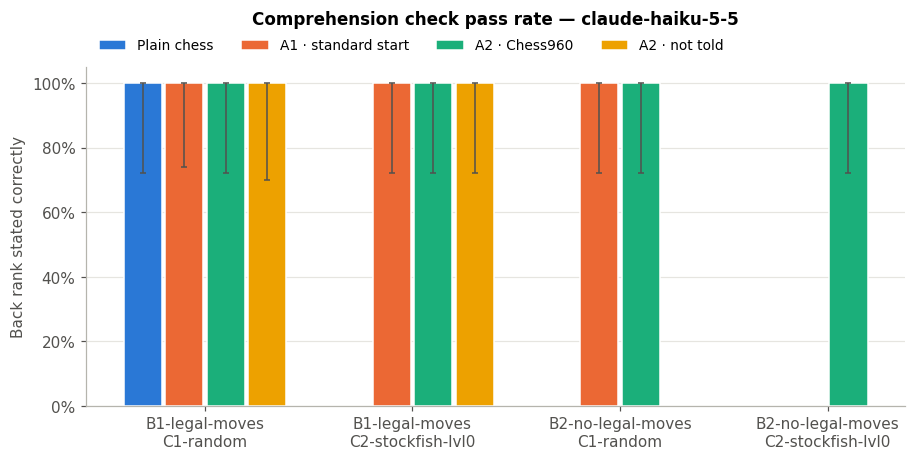

,model,panel,start,passed,checked,pass_rate,lo,hi
0,claude-haiku-5-5,B1-legal-moves | C1-random,Plain chess,10,10,1.000,0.722,1.000
1,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start,11,11,1.000,0.741,1.000
2,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · Chess960,10,10,1.000,0.722,1.000
3,claude-haiku-5-5,B1-legal-moves | C1-random,A2 · not told,9,9,1.000,0.701,1.000
4,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start,10,10,1.000,0.722,1.000
5,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · Chess960,10,10,1.000,0.722,1.000
6,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A2 · not told,10,10,1.000,0.722,1.000
7,claude-haiku-5-5,B2-no-legal-moves | C1-random,A1 · standard start,10,10,1.000,0.722,1.000
8,claude-haiku-5-5,B2-no-legal-moves | C1-random,A2 · Chess960,10,10,1.000,0.722,1.000
9,claude-haiku-5-5,B2-no-legal-moves | C2-stockfish-lvl0,A2 · Chess960,10,10,1.000,0.722,1.000


games                    win_rate                   loss_rate                   illegal_per_turn                    \
subset                                                                        all games passed check only all games passed check only all games passed check only        all games passed check only   
model            panel                                 start                                                                                                                                           
claude-haiku-5-5 B1-legal-moves | C1-random            standard-chess                10                10     0.900             0.900     0.000             0.000            0.007             0.007   
                                                       A1-standard-pos518            11                11     1.000             1.000     0.000             0.000            0.015             0.015   
                                                       A2-chess960                   10                10     0.900             0.900     0.000             0.000            0.007             0.007   
                                                       A2-chess960-uninformed         9                 9     0.889             0.889     0.000             0.000            0.014             0.014   
                 B1-legal-moves | C2-stockfish-lvl0    A1-standard-pos518            10                10     0.200             0.200     0.800             0.800            0.043             0.043   
                                                       A2-chess960                   10                10     0.100             0.100     0.900             0.900            0.053             0.053   
                                                       A2-chess960-uninformed        10                10     0.000             0.000     0.800             0.800            0.040             0.040   
                 B2-no-legal-moves | C1-random         A1-standard-pos518            10                10     1.000             1.000     0.000             0.000            0.021             0.021   
                                                       A2-chess960                   10                10     1.000             1.000     0.000             0.000            0.010             0.010   
                 B2-no-legal-moves | C2-stockfish-lvl0 A2-chess960                   10                10     0.100             0.100     0.700             0.700            0.088             0.088   

                                                                                   acpl                    
subset                                                                        all games passed check only  
model            panel                                 start                                               
claude-haiku-5-5 B1-legal-moves | C1-random            standard-chess            40.858            40.858  
                                                       A1-standard-pos518        71.290            71.290  
                                                       A2-chess960               50.963            50.963  
                                                       A2-chess960-uninformed    80.245            80.245  
                 B1-legal-moves | C2-stockfish-lvl0    A1-standard-pos518        79.219            79.219  
                                                       A2-chess960              110.162           110.162  
                                                       A2-chess960-uninformed   111.378           111.378  
                 B2-no-legal-moves | C1-random         A1-standard-pos518        28.021            28.021  
                                                       A2-chess960               49.642            49.642  
                 B2-no-legal-moves | C2-stockfish-lvl0 A2-chess960              106.810           106.810

In [58]:
checked = games[games["comprehension_checked"]]
if checked.empty:
    print("No comprehension checks in these runs (use --comprehension-check).")
else:
    comp = (checked.groupby(["model", "panel", "start"], observed=True)["comprehension_correct"]
            .agg(passed=lambda s: int(s.fillna(False).astype(bool).sum()), checked="size").reset_index())
    ci = comp.apply(lambda r: wilson(r["passed"], r["checked"]), axis=1, result_type="expand")
    comp[["pass_rate", "lo", "hi"]] = ci
    for model in MODELS:
        t = comp[comp["model"] == model]
        if t.empty:
            continue
        fig, ax = plt.subplots(figsize=(max(6, 2.4 * t["panel"].nunique()), 4))
        grouped_bars(ax, t, "pass_rate", "lo", "hi")
        ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.set_ylabel("Back rank stated correctly")
        ax.set_title(f"Comprehension check pass rate — {model}", pad=28)
        savefig(fig, f"comprehension_{model}"); plt.show()
    display(comp.assign(start=comp["start"].map(START_LABEL)))

    passed = checked[checked["comprehension_correct"] == True]
    both = pd.concat([
        games.assign(subset="all games"),
        passed.assign(subset="passed check only"),
    ])
    display(both.groupby(["model", "panel", "start", "subset"], observed=True)
            .agg(games=("win", "size"), win_rate=("win", "mean"), loss_rate=("loss", "mean"),
                 illegal_per_turn=("illegal_per_turn", "mean"), acpl=("all_acpl", "mean"))
            .unstack("subset"))

## 5. Move quality (Stockfish)

Average centipawn loss (lower is better), blunder rate (≥300 cp) and best-move match, split into the **opening (plies 1–15)**
and **later** plies. If the model recites openings, its standard-start opening play should look much better than its Chess960
opening play, while later plies should be closer.

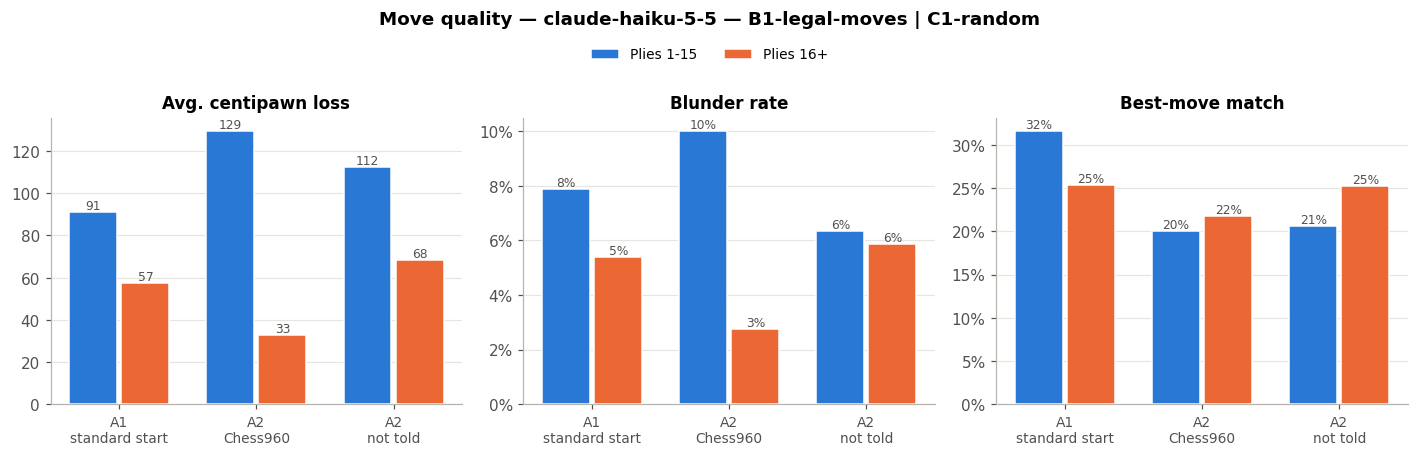

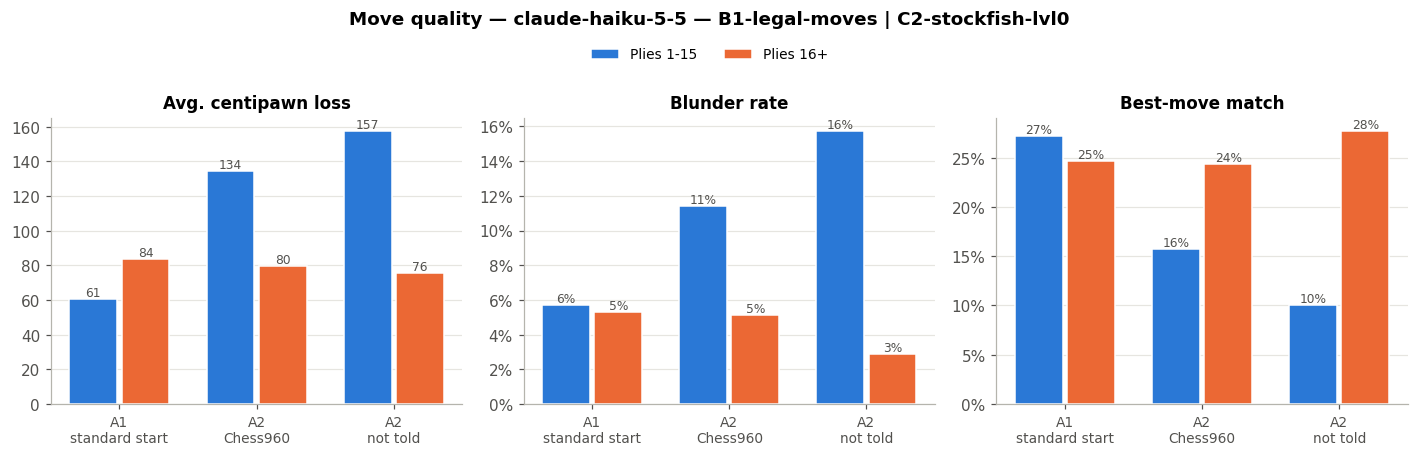

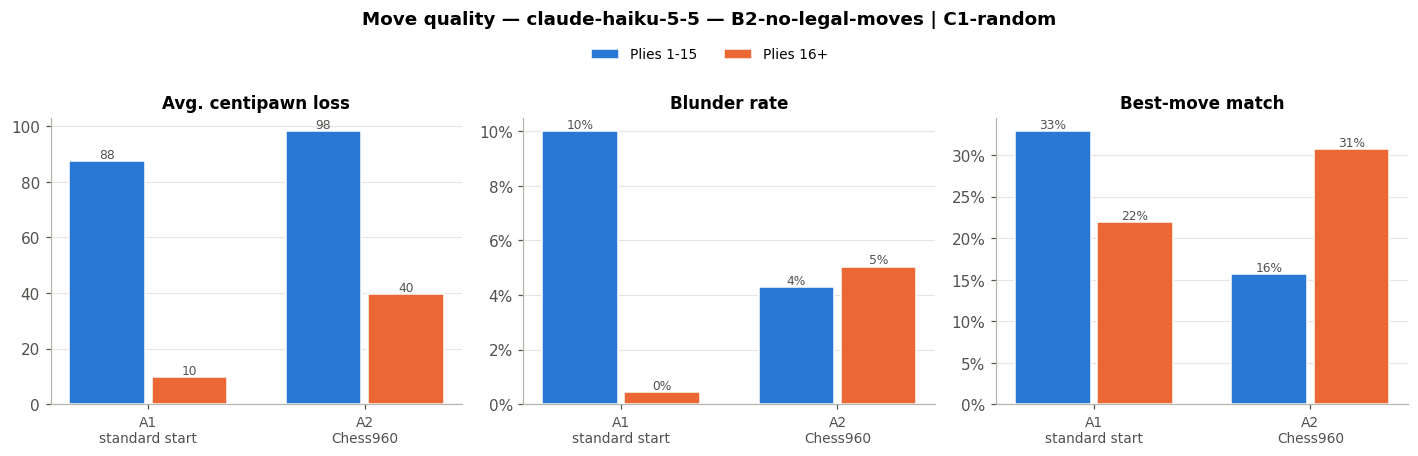

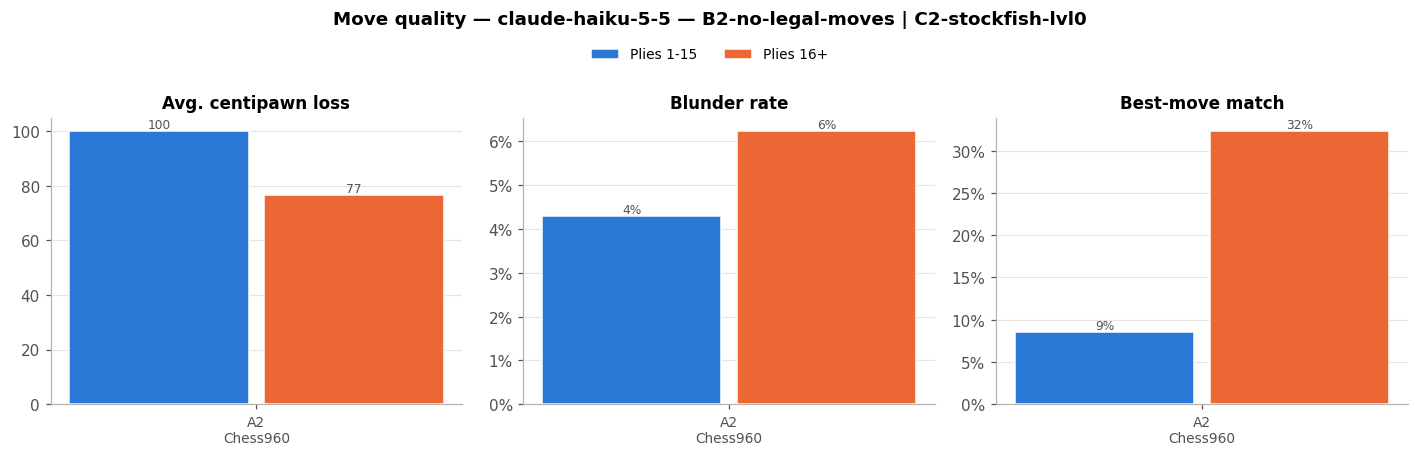

acpl         best_move_rate         blunder_rate         moves        
phase                                                                       later opening          later opening        later opening later opening
model            panel                                 start                                                                                       
claude-haiku-5-5 B1-legal-moves | C1-random            A1 · standard start 57.470  91.184          0.254   0.316        0.054   0.079   185      76
                                                       A2 · Chess960       32.585 129.414          0.218   0.200        0.028   0.100   289      70
                                                       A2 · not told       68.433 112.444          0.252   0.206        0.059   0.064   238      63
                 B1-legal-moves | C2-stockfish-lvl0    A1 · standard start 83.945  60.729          0.247   0.271        0.053   0.057   470      70
                                                       A2 · Chess960       79.692 134.271          0.243   0.157        0.051   0.114   214      70
                                                       A2 · not told       75.735 157.414          0.277   0.100        0.029   0.157   347      70
                 B2-no-legal-moves | C1-random         A1 · standard start  9.825  87.543          0.219   0.329        0.004   0.100   228      70
                                                       A2 · Chess960       39.500  98.186          0.307   0.157        0.050   0.043   238      70
                 B2-no-legal-moves | C2-stockfish-lvl0 A2 · Chess960       76.626 100.000          0.323   0.086        0.062   0.043   353      70

In [68]:
def weighted(g, metric, phase):
    n = g[f"{phase}_moves"].fillna(0)
    v = g[f"{phase}_{metric}"]
    mask = v.notna() & (n > 0)
    return np.average(v[mask], weights=n[mask]) if mask.any() else np.nan

if games.get("all_acpl") is None or games["all_acpl"].isna().all():
    print("No move-quality data - run analyze_960.py with Stockfish (without --no-engine).")
else:
    rows = []
    for (model, panel, start), g in games.groupby(["model", "panel", "start"], observed=True):
        for phase in ("opening", "later"):
            rows.append({"model": model, "panel": panel, "start": start, "phase": phase,
                         "moves": int(g[f"{phase}_moves"].fillna(0).sum()),
                         "acpl": weighted(g, "acpl", phase),
                         "blunder_rate": weighted(g, "blunder_rate", phase),
                         "best_move_rate": weighted(g, "best_move_rate", phase)})

    mq = pd.DataFrame(rows)
    mq = mq[mq["start"].astype(str) != "standard-chess"]   # hide plain chess
    
    metrics = [("acpl", "Avg. centipawn loss", "{:.0f}"), ("blunder_rate", "Blunder rate", "{:.0%}"),
               ("best_move_rate", "Best-move match", "{:.0%}")]
    for model in MODELS:
        t = mq[mq["model"] == model]
        for panel in panels_for(t):
            tp = t[t["panel"] == panel]
            starts = [s for s in START_ORDER if s in set(tp["start"])]
            fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
            for ax, (metric, label, fmt) in zip(axes, metrics):
                x = np.arange(len(starts)); w = 0.38
                for k, phase in enumerate(("opening", "later")):
                    vals = tp[tp["phase"] == phase].set_index("start").reindex(starts)[metric].to_numpy(dtype=float)
                    ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=PHASE_COLOR[phase], edgecolor="white", linewidth=1,
                           label="Plies 1-15" if phase == "opening" else "Plies 16+")
                    for xi, v in zip(x + (k - 0.5) * w, vals):
                        if not np.isnan(v):
                            ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=8, color="#52514e")
                ax.set_xticks(x); ax.set_xticklabels([START_LABEL[s].replace(" · ", "\n") for s in starts], fontsize=9)
                ax.set_title(label)
                if metric != "acpl":
                    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
            fig.suptitle(f"Move quality — {model} — {panel}", y=1.08, fontweight="semibold")
            handles, labels = axes[0].get_legend_handles_labels()
            fig.legend(handles, labels, ncols=2, loc="upper center", bbox_to_anchor=(0.5, 1.02), fontsize=9)
            fig.tight_layout()
            savefig(fig, f"move_quality_{model}_{panel.replace(' | ', '_')}"); plt.show()
    display(mq.assign(start=mq["start"].map(START_LABEL))
            .pivot_table(index=["model", "panel", "start"], columns="phase",
                         values=["acpl", "blunder_rate", "best_move_rate", "moves"], observed=True))

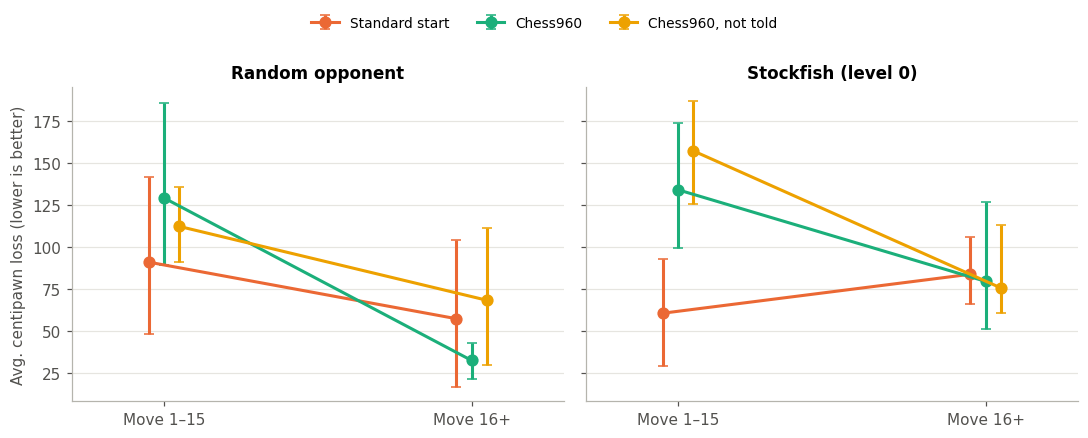

In [78]:
moves = pd.read_csv(ANALYSIS_DIR / "moves.csv")
moves = moves[(moves["start"] != "standard-chess") & (moves["legal_moves"] == "B1-legal-moves")]

PANELS = [("C1-random", "Random opponent"), ("C2-stockfish-lvl0", "Stockfish (level 0)")]
STARTS = ["A1-standard-pos518", "A2-chess960", "A2-chess960-uninformed"]
NAMES = {"A1-standard-pos518": "Standard start", "A2-chess960": "Chess960",
         "A2-chess960-uninformed": "Chess960, not told"}
rng = np.random.default_rng(960)

def mean_ci(d, n_boot=2000):
    # Move-weighted mean with a 95% bootstrap interval over games
    per_game = d.groupby("log_file")["cp_loss"].agg(["sum", "count"])
    s, c = per_game["sum"].to_numpy(), per_game["count"].to_numpy()
    idx = rng.integers(0, len(s), (n_boot, len(s)))
    boots = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    return s.sum() / c.sum(), *np.percentile(boots, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (opp, title) in zip(axes, PANELS):
    d_opp = moves[moves["opponent"] == opp]
    for k, start in enumerate(STARTS):
        d = d_opp[d_opp["start"] == start]
        if d.empty:
            continue
        stats_ = [mean_ci(d[d["phase"] == ph]) for ph in ("opening", "later")]
        m = np.array([s[0] for s in stats_])
        lo = np.array([s[1] for s in stats_]); hi = np.array([s[2] for s in stats_])
        xs = np.array([0, 1]) + (k - 1) * 0.05
        ax.errorbar(xs, m, yerr=[m - lo, hi - m], color=START_COLOR[start], marker="o",
                    markersize=7, linewidth=2, capsize=3, label=NAMES[start])
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Move 1–15", "Move 16+"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(title)
axes[0].set_ylabel("Avg. centipawn loss (lower is better)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncols=3, fontsize=9,
           bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9))   # leave room at the top for the legend

## 5b. Opening-gap test (RQ2)

If the model relies on memorised opening theory, moving from the standard start (A1) to Chess960 (A2) should hurt
its **opening** play (plies 1–15) more than its **later** play. The test statistic is the difference-in-differences of
average centipawn loss (ACPL):

  **DiD = (ACPL<sub>A2, opening</sub> − ACPL<sub>A1, opening</sub>) − (ACPL<sub>A2, later</sub> − ACPL<sub>A1, later</sub>)**

A positive DiD means the Chess960 penalty is concentrated in the opening. The 95% interval and p-value come from
bootstrapping whole games (moves within a game are not independent). Best read on the engine-opponent games; against the
random player there is little opening theory to apply even from the standard start.

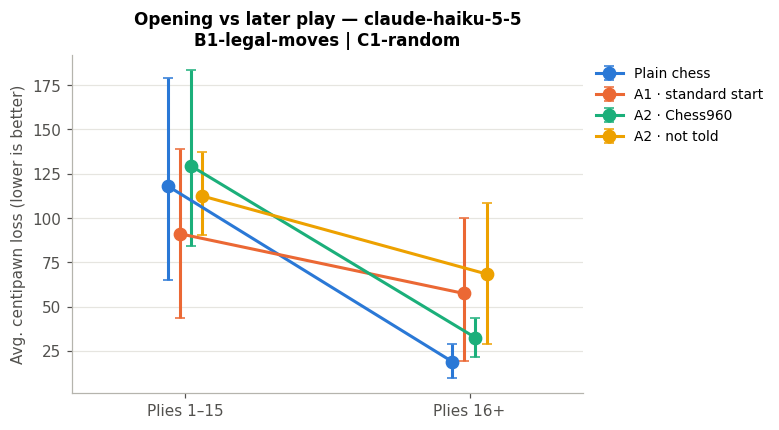

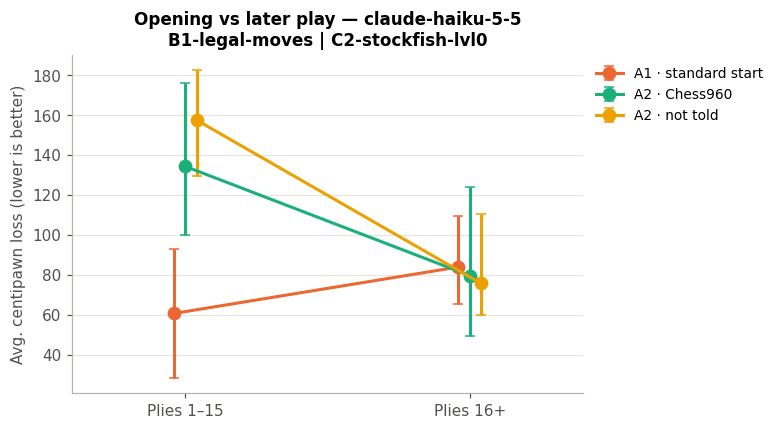

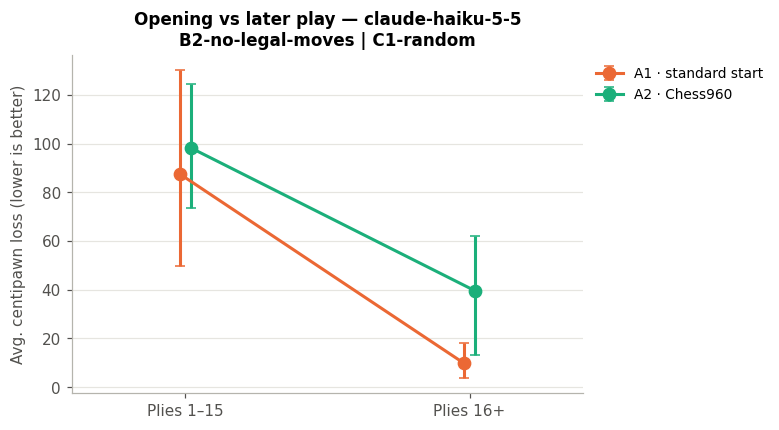

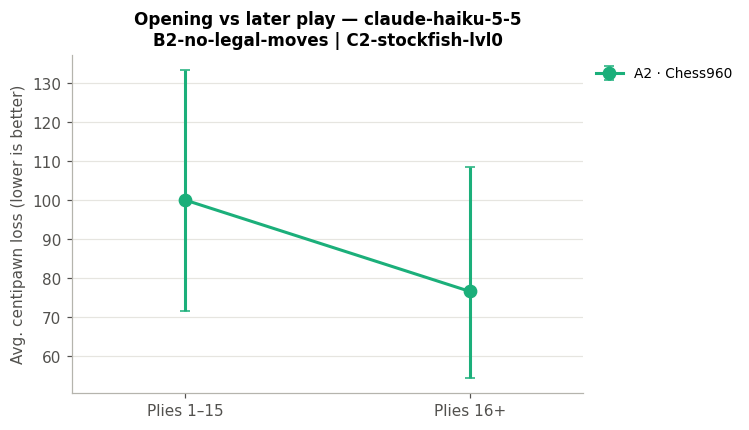

,model,panel,comparison,games,opening_ACPL,later_ACPL,DiD,ci_low,ci_high,p_bootstrap
0,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start → A2 · Chess960,11 / 10,91 → 129,57 → 33,63.116,-6.829,141.816,0.083
1,claude-haiku-5-5,B1-legal-moves | C1-random,A1 · standard start → A2 · not told,11 / 9,91 → 112,57 → 68,10.298,-55.447,76.243,0.773
2,claude-haiku-5-5,B1-legal-moves | C1-random,Plain chess → A2 · Chess960,10 / 10,118 → 129,19 → 33,-2.171,-82.525,75.215,0.940
3,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start → A2 · Chess960,10 / 10,61 → 134,84 → 80,77.796,13.428,136.709,0.018
4,claude-haiku-5-5,B1-legal-moves | C2-stockfish-lvl0,A1 · standard start → A2 · not told,10 / 10,61 → 157,84 → 76,104.896,44.814,154.411,0.002
5,claude-haiku-5-5,B2-no-legal-moves | C1-random,A1 · standard start → A2 · Chess960,10 / 10,88 → 98,10 → 40,-19.033,-66.204,23.307,0.423


In [60]:
moves_path = ANALYSIS_DIR / "moves.csv"
moves = pd.read_csv(moves_path) if moves_path.exists() and moves_path.stat().st_size > 0 else pd.DataFrame()
DID_PAIRS = [("A1-standard-pos518", "A2-chess960"), ("A1-standard-pos518", "A2-chess960-uninformed"),
             ("standard-chess", "A2-chess960")]
N_BOOT = 2000
rng = np.random.default_rng(960)

def phase_means(df):
    m = df.groupby("phase")["cp_loss"].mean()
    return m.get("opening", np.nan), m.get("later", np.nan)

def did_of(base, other):
    bo, bl = phase_means(base); oo, ol = phase_means(other)
    return (oo - bo) - (ol - bl)

def resample_games(df):
    keys = df[["log_file", "side"]].drop_duplicates().to_numpy()
    pick = keys[rng.integers(0, len(keys), len(keys))]
    parts = [df[(df["log_file"] == f) & (df["side"] == s)] for f, s in pick]
    return pd.concat(parts) if parts else df.iloc[0:0]

if moves.empty:
    print("No per-move data - run analyze_960.py with Stockfish (without --no-engine).")
else:
    moves["panel"] = moves["legal_moves"] + " | " + moves["opponent"]
    did_rows = []
    for (model, panel), g in moves.groupby(["model", "panel"]):
        for base_s, other_s in DID_PAIRS:
            base, other = g[g["start"] == base_s], g[g["start"] == other_s]
            if base.empty or other.empty or base["phase"].nunique() < 2 or other["phase"].nunique() < 2:
                continue
            est = did_of(base, other)
            boots = np.array([did_of(resample_games(base), resample_games(other)) for _ in range(N_BOOT)])
            boots = boots[~np.isnan(boots)]
            p = 2 * min((boots <= 0).mean(), (boots >= 0).mean()) if len(boots) else np.nan
            bo, bl = phase_means(base); oo, ol = phase_means(other)
            did_rows.append({"model": model, "panel": panel,
                             "comparison": f"{START_LABEL[base_s]} → {START_LABEL[other_s]}",
                             "games": f"{base[['log_file','side']].drop_duplicates().shape[0]} / "
                                      f"{other[['log_file','side']].drop_duplicates().shape[0]}",
                             "opening_ACPL": f"{bo:.0f} → {oo:.0f}", "later_ACPL": f"{bl:.0f} → {ol:.0f}",
                             "DiD": est, "ci_low": np.percentile(boots, 2.5) if len(boots) else np.nan,
                             "ci_high": np.percentile(boots, 97.5) if len(boots) else np.nan, "p_bootstrap": min(1.0, p)})

        # Interaction plot: ACPL by phase, one line per start condition (95% bootstrap CI over games)
        starts = [s for s in START_ORDER if s in set(g["start"])]
        if not starts:
            continue
        fig, ax = plt.subplots(figsize=(6, 4))
        for k, start in enumerate(starts):
            d = g[g["start"] == start]
            means, lo, hi = [], [], []
            for phase in ("opening", "later"):
                dp = d[d["phase"] == phase]
                if dp.empty:
                    means.append(np.nan); lo.append(np.nan); hi.append(np.nan); continue
                bs = [resample_games(dp)["cp_loss"].mean() for _ in range(300)]
                means.append(dp["cp_loss"].mean()); lo.append(np.nanpercentile(bs, 2.5)); hi.append(np.nanpercentile(bs, 97.5))
            xs = np.array([0, 1]) + (k - (len(starts) - 1) / 2) * 0.04
            means, lo, hi = map(np.array, (means, lo, hi))
            ax.errorbar(xs, means, yerr=np.clip([means - lo, hi - means], 0, None), color=START_COLOR[start],
                        marker="o", markersize=8, linewidth=2, capsize=3, label=START_LABEL[start])
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Plies 1–15", "Plies 16+"]); ax.set_xlim(-0.4, 1.4)
        ax.set_ylabel("Avg. centipawn loss (lower is better)")
        ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
        ax.set_title(f"Opening vs later play — {model}\n{panel}")
        savefig(fig, f"opening_gap_{model}_{panel.replace(' | ', '_')}"); plt.show()

    did_table = pd.DataFrame(did_rows)
    if did_table.empty:
        print("Need A1 and A2 games with moves in both phases in the same cell.")
    else:
        display(did_table)

## 6. Engine baseline (is Chess960 just harder?)

Engine-vs-engine runs (`--opponent stockfish --player stockfish`) are not LLM games, so they are read straight from the
`_aggregate_results.json` files. If the engine's results barely change between the standard start and the Chess960 sample,
a large drop for the LLM cannot be explained by Chess960 being inherently harder.

,start,levels,games,white_win_rate,draw_rate,avg_plies,folder
0,A1 · standard start,0 vs 0,30,0.567,0.167,113.667,_logs/chess960/A1-pos518_B1-legal/engine_vs_en...
1,A2 · Chess960,0 vs 0,30,0.300,0.167,115.300,_logs/chess960/A2-10pos_B1-legal/engine_vs_eng...


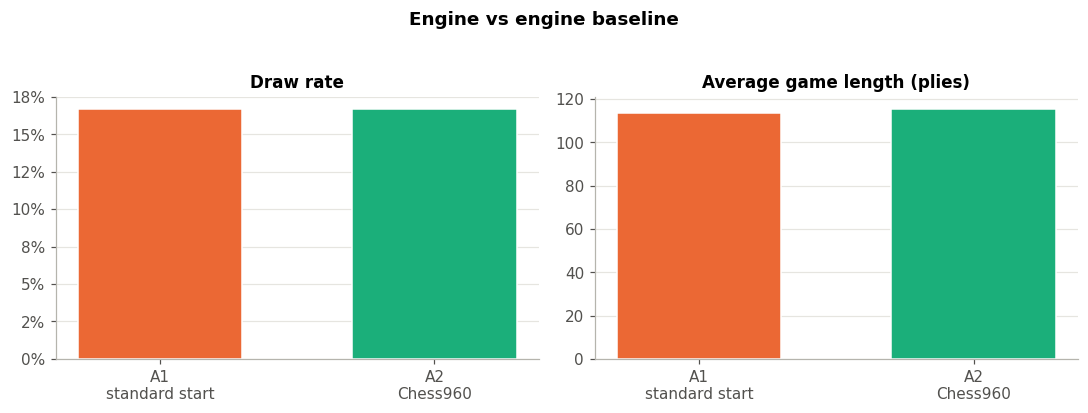

In [63]:
engine_rows = []
for path in LOG_DIR.rglob("_aggregate_results.json"):
    try:
        agg = json.loads(path.read_text())
    except (OSError, json.JSONDecodeError):
        continue
    s = agg.get("experiment_settings", {})
    types = {s.get("white_player_type"), s.get("black_player_type")}
    if not types or not types <= {"CHESS_ENGINE_STOCKFISH", "CHESS_ENGINE_DRAGON"}:
        continue
    positions = s.get("positions") or []
    start = ("standard-chess" if not s.get("chess960")
             else "A1-standard-pos518" if set(positions) == {518} else "A2-chess960")
    n = agg.get("total_games", 0)
    engine_rows.append({
        "start": START_LABEL[start], "levels": f"{s.get('white_engine_level')} vs {s.get('black_engine_level')}",
        "games": n, "white_win_rate": agg["white_wins"] / n if n else np.nan,
        "draw_rate": agg["draws"] / n if n else np.nan, "avg_plies": agg.get("average_moves"),
        "folder": str(path.parent),
    })

if engine_rows:
    eng = pd.DataFrame(engine_rows).sort_values(["levels", "start"])
    display(eng)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, (col, label) in zip(axes, [("draw_rate", "Draw rate"), ("avg_plies", "Average game length (plies)")]):
        grp = eng.groupby("start")[col].mean().reindex([START_LABEL[s] for s in START_ORDER]).dropna()
        colors = [START_COLOR[k] for k, v in START_LABEL.items() if v in grp.index]
        ax.bar(range(len(grp)), grp.to_numpy(), 0.6, color=colors, edgecolor="white")
        ax.set_xticks(range(len(grp))); ax.set_xticklabels([g.replace(" · ", "\n") for g in grp.index])
        ax.set_title(label)
        if col == "draw_rate":
            ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    fig.suptitle("Engine vs engine baseline", fontweight="semibold", y=1.03)
    fig.tight_layout(); savefig(fig, "engine_baseline"); plt.show()
else:
    print(f"No engine-vs-engine runs found under {LOG_DIR}.")

## Export

All figures above are saved as PNG in `_analysis/figures/`. The cell below writes the summary tables next to them.

In [64]:
outcome.assign(start=outcome["start"].map(START_LABEL)).to_csv(ANALYSIS_DIR / "table_outcomes.csv", index=False)
per_turn.reset_index().to_csv(ANALYSIS_DIR / "table_illegal_per_turn.csv", index=False)
if not comparisons.empty:
    comparisons.to_csv(ANALYSIS_DIR / "table_comparisons.csv", index=False)
if "did_table" in globals() and not did_table.empty:
    did_table.to_csv(ANALYSIS_DIR / "table_opening_gap.csv", index=False)
if "sp" in globals() and not sp.empty:
    sp.to_csv(ANALYSIS_DIR / "table_standard_pattern.csv", index=False)
print("Saved tables and figures to", ANALYSIS_DIR.resolve())

Saved tables and figures to /Users/claes/Uni/Udveksling/NLP/llm_chess960/_analysis
